# sidewise · dataset municipal consolidado v0.3

**Objetivo:** incorporar empleo registrado, recurso eólico y estado de las masas de agua subterránea a los 25 indicadores anteriores. Una fila por municipio; no se inventan datos ni se construye un ranking sin criterios aprobados.

Se conserva la base v0.2 y se añaden 11 indicadores. Los registros mensuales completos del SEPE se entregan aparte para no perder detalle. Las tablas municipales son aptas para exploración y para conectar la aplicación; no acreditan la viabilidad de una parcela.

**Fecha de preparación:** 14/11/2026. Ejecutar desde la raíz del proyecto o desde `notebooks`. Los originales incluidos permiten repetir esta ampliación sin red. Los notebooks 01 y 02 documentan las etapas anteriores. El muestreo eólico puede tardar unos minutos.

In [8]:
from pathlib import Path
import re, json, hashlib, zipfile, math, sys
from datetime import date
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import rasterio
from rasterio.windows import Window
from rasterio.features import geometry_mask
from pyproj import Transformer
import xlrd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT = ROOT.parent
assert (ROOT/'data/processed/sitewise_v02/valores.csv').exists(), 'Abrir dentro del proyecto con los datos extraídos'
RAW=ROOT/'data/raw/sitewise_v03'; OUT=ROOT/'data/processed/sitewise_v03'; DOC=ROOT/'docs/data/sitewise_v03'
OUT.mkdir(parents=True,exist_ok=True); DOC.mkdir(parents=True,exist_ok=True)
BASE=ROOT/'data/processed/sitewise_v02'
municipios=pd.read_csv(BASE/'municipios.csv',dtype={'cod_ine':str,'cod_provincia':str})
geo=gpd.read_file(ROOT/'data/processed/sitewise_v01/municipios.geojson')
geo['cod_ine']=geo.cod_ine.astype(str).str.zfill(5)
assert len(municipios)==8132 and municipios.cod_ine.is_unique and set(geo.cod_ine)==set(municipios.cod_ine)
MASTER=set(municipios.cod_ine)
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold'})
def save(df,name): df.to_csv(OUT/name,index=False,encoding='utf-8-sig')
def digest(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
print('Municipios de referencia:',len(municipios))

Municipios de referencia: 8132


## 1. Lectura y trazabilidad del SEPE

Leemos los XLS directamente del ZIP. Identificamos el mes en las cabeceras, nunca en el nombre del archivo. Eliminamos únicamente duplicados con el mismo SHA-256; dos ficheros distintos para el mismo mes detendrían el proceso.

`<5` significa una cifra protegida, no cero ni una estimación de 2,5. Los blancos también se conservan como ausentes. Guardamos el texto original, el estado de cada celda, archivo, hoja y fila. Los totales provinciales y las filas sin municipio van separados y no se asignan artificialmente a municipios.

El paro registrado es un stock administrativo al cierre del mes; los contratos son un flujo de contratos, no personas únicas. No equivalen a la tasa de paro ni a una bolsa de trabajadores disponibles.

In [9]:
PARO=['paro_total','paro_hombres_menor25','paro_hombres_25_44','paro_hombres_45_mas','paro_mujeres_menor25','paro_mujeres_25_44','paro_mujeres_45_mas','paro_agricultura','paro_industria','paro_construccion','paro_servicios','paro_sin_empleo_anterior']
CONTR=['contratos_total','contratos_hombres_inicial_indefinido','contratos_hombres_inicial_temporal','contratos_hombres_convertido_indefinido','contratos_mujeres_inicial_indefinido','contratos_mujeres_inicial_temporal','contratos_mujeres_convertido_indefinido','contratos_agricultura','contratos_industria','contratos_construccion','contratos_servicios']
MONTHS={m:i+1 for i,m in enumerate('ENERO FEBRERO MARZO ABRIL MAYO JUNIO JULIO AGOSTO SEPTIEMBRE OCTUBRE NOVIEMBRE DICIEMBRE'.split())}
pattern=re.compile(r'('+'|'.join(MONTHS)+r')\s+(20\d{2})')
def parse_cell(v):
    if isinstance(v,(int,float)):
        assert np.isfinite(v) and v>=0 and float(v).is_integer(), v
        return int(v),'publicado'
    s=str(v).strip()
    if s=='<5':return pd.NA,'ocultado_menor5'
    if not s:return pd.NA,'blanco_fuente'
    raise ValueError(f'Valor no reconocido: {v!r}')
records={'paro':[],'contratos':[]}; province=[]; no_muni=[]; files=[]; hashes={}; periods={}
with zipfile.ZipFile(RAW/'ESTADISTICA_MUNICIPIOS.zip') as z:
    for fname in z.namelist():
        if not fname.lower().endswith('.xls'):continue
        payload=z.read(fname); sha=hashlib.sha256(payload).hexdigest()
        if sha in hashes:
            files.append({'archivo':fname,'sha256':sha,'estado':'duplicado_exacto','duplicado_de':hashes[sha]});continue
        hashes[sha]=fname; book=xlrd.open_workbook(file_contents=payload,on_demand=True)
        per_file=set(); ns={'paro':0,'contratos':0}
        for sn in book.sheet_names():
            normalized=sn.strip().upper()
            kind='paro' if normalized.startswith('PARO') else 'contratos' if normalized.startswith('CONTR') else None
            sh=book.sheet_by_name(sn)
            if kind is None:
                if normalized.startswith('NO CONSTA'):
                    no_muni.append({'archivo':fname,'hoja':sn,'contenido_json':json.dumps([sh.row_values(r) for r in range(sh.nrows)],ensure_ascii=False)})
                book.unload_sheet(sn);continue
            metrics=PARO if kind=='paro' else CONTR
            hits=set()
            for r in range(min(8,sh.nrows)):
                for v in sh.row_values(r):
                    for mo,yr in pattern.findall(str(v).upper()):hits.add(f'{yr}-{MONTHS[mo]:02d}')
            assert len(hits)==1,(fname,sn,hits)
            period=hits.pop(); per_file.add(period);ns[kind]+=1
            assert str(sh.cell_value(4,2)).strip().upper()=='TOTAL'
            assert sh.ncols>=len(metrics)+2
            for r in range(8,sh.nrows):
                vals=sh.row_values(r); rawcode=vals[0]
                is_code=isinstance(rawcode,(float,int)) and rawcode>0 and float(rawcode).is_integer()
                if not is_code and not isinstance(vals[2],(float,int)):continue
                row={'periodo':period,'cod_ine':f'{int(rawcode):05d}' if is_code else '', 'nombre_fuente':str(vals[1]).strip(),'archivo':fname,'hoja':sn,'fila_excel':r+1,'sha256_archivo':sha,'naturaleza_fila':'original','codigos_fuente':f'{int(rawcode):05d}' if is_code else ''}
                for j,m in enumerate(metrics,2):
                    row[m],row['estado__'+m]=parse_cell(vals[j]);row['original__'+m]=vals[j]
                if is_code:records[kind].append(row)
                else:province.append(dict(row,tipo=kind))
            book.unload_sheet(sn)
        book.release_resources()
        assert len(per_file)==1 and ns=={'paro':52,'contratos':52},(fname,per_file,ns)
        period=per_file.pop();assert period not in periods,(period,fname,periods.get(period));periods[period]=fname
        assert pd.Period(period,'M').end_time.date()<date(2026,11,14)
        files.append({'archivo':fname,'sha256':sha,'estado':'procesado','periodo':period})
raw_tables={}
for kind,metrics in [('paro',PARO),('contratos',CONTR)]:
    df=pd.DataFrame(records[kind])
    for m in metrics:df[m]=df[m].astype('Int64');df['original__'+m]=df['original__'+m].astype(object)
    assert not df.duplicated(['periodo','cod_ine']).any()
    raw_tables[kind]=df;save(df,f'sepe_{kind}_original.csv.gz')
prov=pd.DataFrame(province);save(prov,'sepe_totales_provinciales.csv.gz');save(pd.DataFrame(no_muni),'sepe_sin_municipio.csv.gz');save(pd.DataFrame(files),'sepe_archivos.csv')
assert len(periods)==22
print('Meses:',min(periods),'a',max(periods),'·',len(periods),'únicos')
display(pd.DataFrame(files).estado.value_counts().rename('archivos').to_frame())

Meses: 2025-01 a 2026-10 · 22 únicos


,archivos
estado,
procesado,22
duplicado_exacto,1


## 2. Armonización de municipios y control aritmético

El SEPE conserva cuatro códigos extinguidos: Cesuras y Oza dos Ríos se agregan a Oza-Cesuras; Cerdedo y Cotobade a Cerdedo-Cotobade. El cruce está documentado en INE y en el Decreto 134/2016 (BOE-A-2017-898). Guardamos las tablas originales intactas y otra versión armonizada.

Solo sumamos una variable cuando las dos celdas de origen están publicadas. Una suma con una celda oculta sigue siendo desconocida. No se deducen cifras protegidas mediante restas. Comprobamos sumas por sexo/edad y sectores exclusivamente en las filas que tienen todos los componentes publicados.

Último mes: 2026-10 · comparación: 2025-10


,tipo,control,filas_comprobables,discrepancias
0,paro,total = paro_hombres_menor25 + paro_hombres_25...,36519,0
1,paro,total = paro_agricultura + paro_industria + pa...,33326,0
2,contratos,total = contratos_hombres_inicial_indefinido +...,17637,0
3,contratos,total = contratos_agricultura + contratos_indu...,14045,0


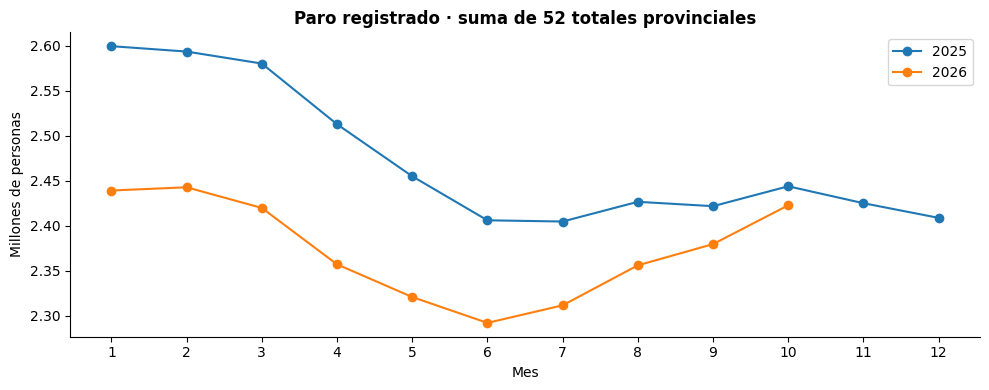

In [10]:
FUSIONS={'15902':['15026','15063'],'36902':['36011','36012']}
crosswalk=pd.DataFrame([{'cod_antiguo':a,'cod_actual':b,'fuente':'https://www.ine.es/intercensal/intercensal.do?search=3&codigoProvincia=15&codigoMunicipio=902' if b=='15902' else 'https://www.boe.es/buscar/doc.php?id=BOE-A-2017-898'} for b,aa in FUSIONS.items() for a in aa]);save(crosswalk,'sepe_correspondencia_codigos.csv')
harmonized={}; checks=[]; fusion_audit=[]
for kind,metrics in [('paro',PARO),('contratos',CONTR)]:
    original=raw_tables[kind]
    assert set(original.cod_ine)-MASTER=={a for aa in FUSIONS.values() for a in aa}
    groups=[metrics[1:7],metrics[7:]]
    for group in groups:
        known=original[[metrics[0]]+group].notna().all(axis=1)
        nbad=int((original.loc[known,metrics[0]]!=original.loc[known,group].sum(axis=1)).sum())
        checks.append({'tipo':kind,'control':'total = '+' + '.join(group),'filas_comprobables':int(known.sum()),'discrepancias':nbad});assert nbad==0
    derived=[]
    for period in sorted(periods):
        for dest,old in FUSIONS.items():
            src=original[(original.periodo==period)&original.cod_ine.isin(old)]
            existing=original[(original.periodo==period)&(original.cod_ine==dest)]
            assert len(src)==2 and existing[metrics].isna().all().all()
            row=src.iloc[0].to_dict();row.update(cod_ine=dest,nombre_fuente=municipios.set_index('cod_ine').loc[dest,'nombre'],naturaleza_fila='agregado_fusion_documentada',codigos_fuente='|'.join(old),hoja='|'.join(src.hoja.astype(str)),fila_excel='|'.join(src.fila_excel.astype(str)))
            for m in metrics:
                public=src['estado__'+m].eq('publicado').all()
                row[m]=int(src[m].sum()) if public else pd.NA
                row['estado__'+m]='agregado_fusion_documentada' if public else 'fusion_con_celdas_no_publicadas'
                row['original__'+m]=''
            derived.append(row)
            fusion_audit.append({'tipo':kind,'periodo':period,'cod_actual':dest,'codigos_fuente':'|'.join(old),'traza':src[['cod_ine','archivo','hoja','fila_excel']].to_json(orient='records',force_ascii=False)})
    keep=original[~original.cod_ine.isin(set(crosswalk.cod_antiguo)|set(FUSIONS))].copy()
    derived=pd.DataFrame(derived)
    for m in metrics:derived[m]=derived[m].astype('Int64');derived['original__'+m]=derived['original__'+m].astype(object)
    df=pd.concat([keep,derived],ignore_index=True).sort_values(['periodo','cod_ine'])
    assert set(df.cod_ine)<=MASTER and not df.duplicated(['periodo','cod_ine']).any()
    harmonized[kind]=df;save(df,f'sepe_{kind}_armonizado.csv.gz')
missing_months=[]
for kind,table in harmonized.items():
    for period,g in table.groupby('periodo'):
        for cod in sorted(MASTER-set(g.cod_ine)):
            missing_months.append({'tipo':kind,'periodo':period,'cod_ine':cod,'estado':'sin_registro_municipal'})
save(pd.DataFrame(missing_months,columns=['tipo','periodo','cod_ine','estado']),'sepe_municipios_sin_fila.csv')
save(pd.DataFrame(checks),'sepe_controles_sumas.csv');save(pd.DataFrame(fusion_audit),'sepe_traza_fusiones.csv')
latest=max(periods); previous=f'{int(latest[:4])-1}{latest[4:]}'
assert previous in periods
employment=municipios[['cod_ine']].copy()
for kind,metrics in [('paro',PARO),('contratos',['contratos_total'])]:
    table=harmonized[kind]; current=table[table.periodo==latest]
    employment=employment.merge(current[['cod_ine']+metrics+['estado__'+m for m in metrics]+['naturaleza_fila']].rename(columns={'naturaleza_fila':'naturaleza_'+kind}),on='cod_ine',how='left',validate='one_to_one')
old=harmonized['paro'].query('periodo == @previous')[['cod_ine','paro_total']].rename(columns={'paro_total':'paro_total_mismo_mes_anterior'})
employment=employment.merge(old,on='cod_ine',how='left',validate='one_to_one')
a=employment.paro_total;b=employment.paro_total_mismo_mes_anterior
employment['paro_variacion_interanual_pct']=((a/b-1)*100).where(a.notna()&b.gt(0)).astype('Float64')
employment['estado__paro_variacion_interanual_pct']=np.select([a.isna()|b.isna(),b.eq(0).fillna(False).to_numpy(dtype=bool)],['sin_datos_comparables','base_cero'],default='derivado_mismos_meses')
for m in PARO+['contratos_total']:employment['estado__'+m]=employment['estado__'+m].fillna('sin_registro_municipal')
employment['periodo']=latest;employment['periodo_comparacion']=previous
save(employment,'empleo_municipal.csv')
print('Último mes:',latest,'· comparación:',previous)
display(pd.DataFrame(checks))
# Gráfico con totales provinciales publicados: nunca reconstruye celdas ocultas municipales.
p=prov[prov.tipo=='paro'].copy();assert p.paro_total.notna().all()
assert p.groupby('periodo').size().eq(52).all()
national=p.groupby('periodo').paro_total.sum().astype(float).reset_index();national['anio']=national.periodo.str[:4];national['mes']=national.periodo.str[5:].astype(int)
fig,ax=plt.subplots()
for year,g in national.groupby('anio'):ax.plot(g.mes,g.paro_total/1e6,marker='o',label=year)
ax.set(title='Paro registrado · suma de 52 totales provinciales',xlabel='Mes',ylabel='Millones de personas',xticks=range(1,13));ax.legend();fig.tight_layout();display(fig);plt.close(fig)

## 3. Recurso eólico a 100 metros

Usamos el TIFF suministrado del Global Wind Atlas. Es un modelo de recurso medio (m/s), no producción eléctrica ni riesgo por rachas. La copia no incorpora en sus metadatos la versión ni el período de simulación: quedan **sin confirmar**; la fecha de descarga no se presenta como fecha de observación.

Calculamos la media ponderada por superficie de las celdas que intersectan cada municipio en una proyección equivalente (EPSG:6933). Los ceros válidos se conservan. No extrapolamos píxeles ausentes: exigimos un 95 % de superficie cubierta; es un criterio metodológico de esta ETL. El GeoJSON nacional y las curvas del ZIP no se reparten entre municipios, porque su escala no permite hacerlo.

Municipios procesados: 2000
Municipios procesados: 4000
Municipios procesados: 6000
Municipios procesados: 8000
Medias utilizables: 8130


,cod_ine,viento_100m_media_m_s,cobertura_viento_pct,pixeles_intersectados_validos,estado
8130,51001,NaN,59.970018,234,cobertura_insuficiente
8131,52001,NaN,0.000000,0,cobertura_insuficiente


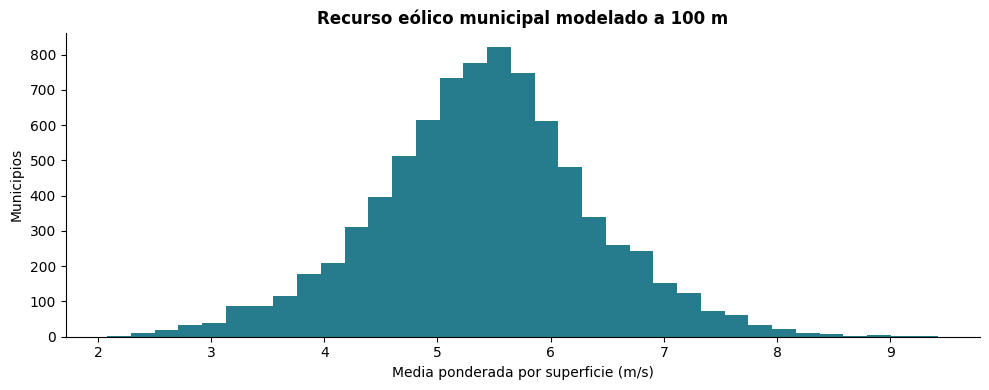

In [11]:
wind_rows=[]
transformer=Transformer.from_crs(4326,6933,always_xy=True)
projected=geo.to_crs(6933)
with rasterio.open(RAW/'ESP_wind-speed_100m.tif') as ds:
    assert ds.crs.to_epsg()==4326 and ds.transform.a>0 and ds.transform.e<0
    raster_info={'crs':str(ds.crs),'width':ds.width,'height':ds.height,'transform':list(ds.transform),'tags':ds.tags(),'version_copia':'no_confirmada','periodo_copia':'no_confirmado','unidad':'m/s según documentación Global Wind Atlas','altura_m':100}
    for i,(idx,row) in enumerate(geo.iterrows()):
        poly=row.geometry; bounds=poly.bounds; fw=ds.window(*bounds)
        c0=max(0,math.floor(fw.col_off));r0=max(0,math.floor(fw.row_off));c1=min(ds.width,math.ceil(fw.col_off+fw.width));r1=min(ds.height,math.ceil(fw.row_off+fw.height))
        valid_area=0.;mean=np.nan;nc=0
        if c1>c0 and r1>r0:
            window=Window(c0,r0,c1-c0,r1-r0);tr=ds.window_transform(window)
            a=ds.read(1,window=window,masked=True).filled(np.nan)
            selected=geometry_mask([shapely.geometry.mapping(poly)],out_shape=a.shape,transform=tr,invert=True,all_touched=True)&np.isfinite(a)
            rr,cc=np.nonzero(selected)
            if len(rr):
                values=a[rr,cc];assert (values>=0).all()
                west=tr.c+cc*tr.a;north=tr.f+rr*tr.e
                xx0,yy0=transformer.transform(west,north+tr.e);xx1,yy1=transformer.transform(west+tr.a,north)
                boxes=shapely.box(xx0,yy0,xx1,yy1);target=projected.loc[idx,'geometry'];shapely.prepare(target)
                inside=shapely.covers(target,boxes);areas=np.zeros(len(boxes));areas[inside]=shapely.area(boxes[inside])
                edge=~inside;areas[edge]=shapely.area(shapely.intersection(boxes[edge],target))
                valid_area=float(areas.sum());nc=int((areas>0).sum())
                if valid_area>0:mean=float(np.sum(values.astype(float)*areas)/valid_area)
        coverage=100*valid_area/projected.loc[idx,'geometry'].area
        assert -.0001<=coverage<=100.001,(row.cod_ine,coverage)
        state='aproximado_modelo' if coverage>=95 else 'cobertura_insuficiente'
        wind_rows.append({'cod_ine':row.cod_ine,'viento_100m_media_m_s':mean if coverage>=95 else np.nan,'cobertura_viento_pct':min(100,coverage),'pixeles_intersectados_validos':nc,'estado':state})
        if (i+1)%2000==0:print('Municipios procesados:',i+1)
wind=pd.DataFrame(wind_rows);save(wind,'viento_municipal.csv')
(DOC/'metadatos_raster_viento.json').write_text(json.dumps(raster_info,ensure_ascii=False,indent=2))
print('Medias utilizables:',wind.viento_100m_media_m_s.notna().sum());display(wind[wind.estado!='aproximado_modelo'])
fig,ax=plt.subplots();ax.hist(wind.viento_100m_media_m_s.dropna(),bins=35,color='#267b8d');ax.set(title='Recurso eólico municipal modelado a 100 m',xlabel='Media ponderada por superficie (m/s)',ylabel='Municipios');fig.tight_layout();display(fig);plt.close(fig)

## 4. Estado de las masas de agua subterránea

El CSV se une por código europeo a las geometrías oficiales del WFS de MITECO (ciclo de planificación 2022–2027). Comprobamos que coinciden los 804 códigos. El ciclo no es la fecha de medición: conservamos por masa los años o intervalos de evaluación.

El diccionario WFD2022 define `2 = buen estado`, `3 = mal estado`, `U = desconocido`. Calculamos qué porcentaje de la **superficie con masas catalogadas dentro del municipio** coincide con al menos una masa en mal estado cuantitativo y químico. Disolvemos solapes para no sumar dos veces los horizontes superpuestos. Incluimos la cobertura municipal para hacer visible el denominador.

Una zona sin masa cartografiada queda desconocida, no en buen estado. El resultado no informa del caudal contratable, de la potabilidad del suministro ni de una concesión industrial.

Municipios con alguna masa catalogada: 7410


,etapa,geometrias_reparadas
0,original,234
1,proyectado,7


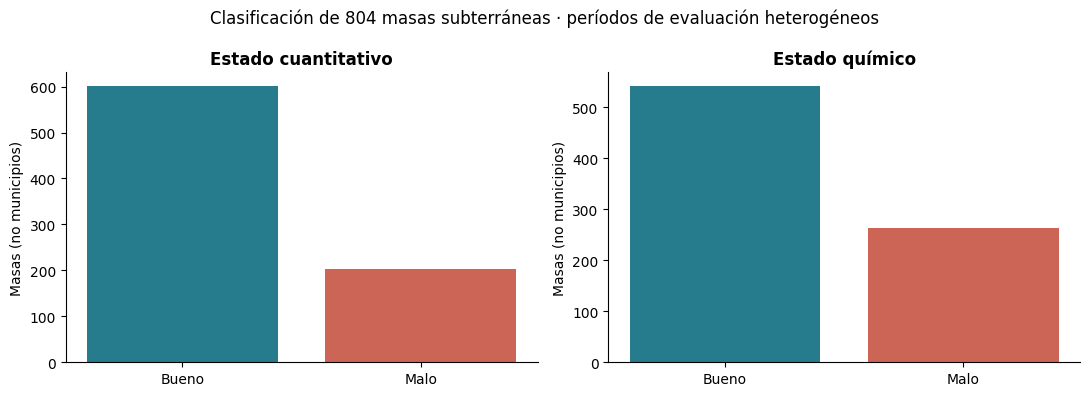

In [12]:
water=pd.read_csv(RAW/'groundwaterbody-estado-masas.csv',sep=';',dtype=str).apply(lambda c:c.str.strip().replace('',pd.NA))
assert len(water)==804 and water.euGroundWaterBodyCode.is_unique
for c in ['gwQuantitativeStatusValue','gwChemicalStatusValue']:
    assert set(water[c].dropna())<={'2','3','U'}
    assert water[c].isin(['2','3']).all(), 'Revisar denominador si hay estados desconocidos'
water_geo=gpd.read_file(RAW/'masas_subterraneas.geojson',columns=['cod_masa','nom_masa','horizontes'])
assert len(water_geo)==804 and water_geo.cod_masa.is_unique
assert set(water_geo.cod_masa)==set(water.euGroundWaterBodyCode)
def polygonal(g):
    if g.geom_type in ['Polygon','MultiPolygon']:return g
    return shapely.union_all([polygonal(p) for p in g.geoms if p.geom_type in ['Polygon','MultiPolygon','GeometryCollection']])
repairs=[]
for stage in ['original','proyectado']:
    if stage=='proyectado':water_geo=water_geo.to_crs(6933)
    invalid=~water_geo.is_valid
    repairs.append({'etapa':stage,'geometrias_reparadas':int(invalid.sum())})
    water_geo.loc[invalid,'geometry']=water_geo.loc[invalid,'geometry'].make_valid().map(polygonal)
assert water_geo.is_valid.all() and (~water_geo.is_empty).all()
water_geo=water_geo.merge(water,left_on='cod_masa',right_on='euGroundWaterBodyCode',validate='one_to_one')
save(water,'masas_subterraneas_atributos.csv');save(pd.DataFrame(repairs),'agua_reparaciones_geometria.csv')
inter=gpd.overlay(projected[['cod_ine','geometry']],water_geo[['cod_masa','gwQuantitativeStatusValue','gwChemicalStatusValue','geometry']],how='intersection',keep_geom_type=True,make_valid=True)
inter['superficie_interseccion_m2']=inter.area
save(pd.DataFrame(inter.drop(columns='geometry')),'agua_subterranea_intersecciones.csv.gz')
def union_area(frame):
    if frame.empty:return pd.Series(dtype=float)
    return frame[['cod_ine','geometry']].dissolve(by='cod_ine').area
mapped=union_area(inter);badq=union_area(inter[inter.gwQuantitativeStatusValue=='3']);badc=union_area(inter[inter.gwChemicalStatusValue=='3'])
ground=municipios[['cod_ine']].copy();ground['superficie_masas_m2']=ground.cod_ine.map(mapped)
ground['cobertura_masas_pct']=ground.cod_ine.map(mapped)/ground.cod_ine.map(projected.set_index('cod_ine').area)*100
for metric,series in [('agua_subterranea_mal_estado_cuantitativo_pct',badq),('agua_subterranea_mal_estado_quimico_pct',badc)]:
    area=ground.cod_ine.map(series).fillna(0)
    ground[metric]=area/ground.superficie_masas_m2*100
    assert ground[metric].dropna().between(-.0001,100.0001).all()
    ground[metric]=ground[metric].clip(0,100)
assert ground.cobertura_masas_pct.dropna().le(100.001).all()
ground['cobertura_masas_pct']=ground.cobertura_masas_pct.clip(0,100)
ground['estado']=np.where(ground.superficie_masas_m2.notna(),'calculado_sobre_masas_catalogadas','sin_masa_catalogada')
save(ground,'agua_subterranea_municipal.csv')
print('Municipios con alguna masa catalogada:',ground.superficie_masas_m2.notna().sum());display(pd.DataFrame(repairs))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,c,title in zip(axes,['gwQuantitativeStatusValue','gwChemicalStatusValue'],['Estado cuantitativo','Estado químico']):
    counts=water[c].value_counts().reindex(['2','3'],fill_value=0);ax.bar(['Bueno','Malo'],counts,color=['#267b8d','#cd6557']);ax.set(title=title,ylabel='Masas (no municipios)')
fig.suptitle('Clasificación de 804 masas subterráneas · períodos de evaluación heterogéneos');fig.tight_layout();display(fig);plt.close(fig)

## 5. Consolidación del contrato de datos

Conservamos exactamente los 25 indicadores anteriores y añadimos ocho de empleo (seis recuentos de paro, contratos totales y variación interanual), uno eólico y dos de agua. Todos los municipios tienen una fila por indicador incluso si el valor falta.

`valores.csv` es el formato recomendado para el backend: incluye fuente, fecha, naturaleza, método y estado. `dataset_municipal.csv` facilita exploración y prototipos. Los porcentajes de cobertura son controles, no nuevos criterios del ranking. No se asignan pesos ni se normalizan magnitudes con fechas distintas sin una decisión del equipo.

Consolidado: 8132 municipios · 36 indicadores · 292752 registros


,valores_utilizables,municipios,ausentes
id_indicador,,,
paro_total,6280,8132,1852
paro_agricultura,3113,8132,5019
paro_industria,3527,8132,4605
paro_construccion,3095,8132,5037
paro_servicios,5895,8132,2237
paro_sin_empleo_anterior,3104,8132,5028
contratos_total,4747,8132,3385
paro_variacion_interanual_pct,5745,8132,2387
viento_100m_media_m_s,8130,8132,2


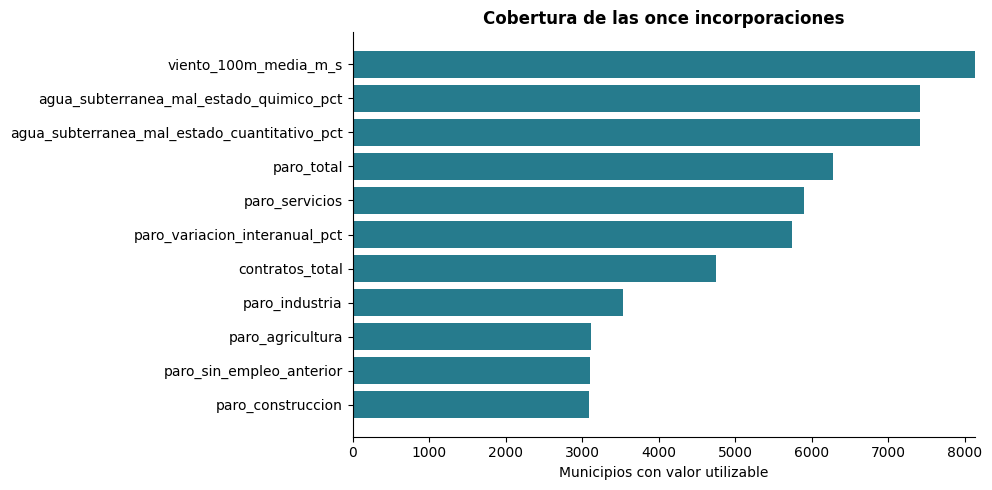

In [13]:
old_values=pd.read_csv(BASE/'valores.csv',dtype={'cod_ine':str},low_memory=False)
old_ind=pd.read_csv(BASE/'indicadores.csv',keep_default_na=False)
SEPE_URL='https://www.sepe.es/HomeSepe/que-es-el-sepe/estadisticas/datos-estadisticos/municipios.html'
WIND_URL='https://globalwindatlas.info/en/download/gis-files'
WATER_URL='https://www.miteco.gob.es/es/cartografia-y-sig/ide/descargas/agua/estado-masas-agua-phc-2022-2027.html'
WFS_URL='https://gis.miteco.gob.es/geoserver/agua/masas_aguasub_2027/wfs?service=WFS&version=2.0.0&request=GetFeature&typenames=agua:masas_aguasub_2027&outputFormat=application/json&srsName=EPSG:4326&count=5000'
newdefs=[];newvalues=[]
def add(metric,label,frame,statecol,block,kind,unit,sense,source,provider,url,when,level,method,nature,limits,extra=''):
    d=dict(id_indicador=metric,nombre=label,bloque=block,tipo=kind,unidad=unit,sentido=sense,fuente_id=source,fuente=provider,url=url,fecha_dato=when,nivel_origen=level,metodo=method,naturaleza=nature,limitaciones=limits)
    newdefs.append(d)
    v=frame[['cod_ine',metric,statecol]].rename(columns={metric:'valor',statecol:'estado'}).copy()
    v['id_indicador']=metric
    for a,b in [('nivel_origen',level),('fecha_dato',when),('fuente_id',source),('naturaleza',nature),('metodo',method),('url_fuente',url),('fuentes_adicionales',extra)]:v[a]=b
    if source=='sepe_municipal':
        derived=v.estado.eq('agregado_fusion_documentada')
        v.loc[derived,'naturaleza']='agregado_fusion_documentada'
    newvalues.append(v[old_values.columns])
labels={'paro_total':'Paro registrado total','paro_agricultura':'Paro registrado: agricultura','paro_industria':'Paro registrado: industria','paro_construccion':'Paro registrado: construcción','paro_servicios':'Paro registrado: servicios','paro_sin_empleo_anterior':'Paro registrado sin empleo anterior','contratos_total':'Contratos registrados totales','paro_variacion_interanual_pct':'Variación interanual del paro registrado'}
for metric,label in labels.items():
    change=metric.endswith('_pct')
    add(metric,label,employment,'estado__'+metric,'empleo','contexto','%' if change else 'contratos' if metric=='contratos_total' else 'personas','depende_actividad','sepe_municipal','SEPE',SEPE_URL,f'{previous} / {latest}' if change else latest,'municipio','(actual / mismo mes año anterior - 1) * 100; base positiva' if change else 'Celda publicada; fusiones de códigos documentadas; sin imputar <5','derivado' if change else 'observado_o_agregado','No es tasa de paro ni personal disponible; blancos y cifras protegidas ausentes; contratos no son personas únicas','sepe_correspondencia_codigos.csv; sepe_traza_fusiones.csv')
add('viento_100m_media_m_s','Recurso eólico medio a 100 m',wind,'estado','energia','recurso','m/s','depende_actividad','gwa_viento','Global Wind Atlas',WIND_URL,'período de la copia no confirmado; descarga 2026-11-14','raster','Media ponderada por intersección de píxeles; EPSG:6933; cobertura >=95%','modelo_agregado','Versión y período de esta copia sin confirmar; no estima producción ni rachas')
for metric,label in [('agua_subterranea_mal_estado_cuantitativo_pct','Superficie catalogada con masa en mal estado cuantitativo'),('agua_subterranea_mal_estado_quimico_pct','Superficie catalogada con masa en mal estado químico')]:
    add(metric,label,ground,'estado','agua','riesgo','%','menor_mejor','miteco_estado_subterraneo','MITECO',WATER_URL,'evaluaciones históricas por masa; ciclo PHC 2022-2027','masa_de_agua','Unión de superficies en mal estado / unión de superficies catalogadas dentro del municipio * 100; WFD 2 bueno, 3 malo','clasificado_y_agregado','Denominador parcial catalogado; ver cobertura; no acredita caudal ni suministro; períodos por masa en atributos',WFS_URL+' ; https://dd.eionet.europa.eu/schema/WFD2022/GWB_2022.xsd/view')
indicators=pd.concat([old_ind,pd.DataFrame(newdefs)],ignore_index=True)
values=pd.concat([old_values]+newvalues,ignore_index=True)
assert indicators.id_indicador.is_unique and len(indicators)==36
assert len(values)==8132*36 and not values.duplicated(['cod_ine','id_indicador']).any()
wide=municipios.merge(values.pivot(index='cod_ine',columns='id_indicador',values='valor'),on='cod_ine',validate='one_to_one')
for column,prefix in [('estado','estado__'),('nivel_origen','nivel_origen__')]:
    wide=wide.merge(values.pivot(index='cod_ine',columns='id_indicador',values=column).add_prefix(prefix),on='cod_ine',validate='one_to_one')
wide=wide.merge(wind[['cod_ine','cobertura_viento_pct']],on='cod_ine',validate='one_to_one').merge(ground[['cod_ine','cobertura_masas_pct']],on='cod_ine',validate='one_to_one')
for df,name in [(municipios,'municipios.csv'),(indicators,'indicadores.csv'),(values,'valores.csv'),(wide,'dataset_municipal.csv')]:save(df,name)
print('Consolidado:',len(municipios),'municipios ·',len(indicators),'indicadores ·',len(values),'registros')
coverage=values.groupby('id_indicador').agg(valores_utilizables=('valor','count'),municipios=('cod_ine','size'))
coverage['ausentes']=coverage.municipios-coverage.valores_utilizables
save(coverage.reset_index(),'cobertura_indicadores.csv')
display(coverage.loc[list(labels)+[d['id_indicador'] for d in newdefs[-3:]]])
fig,ax=plt.subplots(figsize=(10,5));cov=coverage.loc[[d['id_indicador'] for d in newdefs]].sort_values('valores_utilizables');ax.barh(cov.index,cov.valores_utilizables,color='#267b8d');ax.set(xlim=(0,8132),xlabel='Municipios con valor utilizable',title='Cobertura de las once incorporaciones');fig.tight_layout();display(fig);plt.close(fig)

## 6. Verificación y salida

Estas comprobaciones verifican claves, conservación de la base, cruces territoriales y coherencia de ausencias. Una variable sin observación mantiene un estado explicativo. Los controles de sumas no intentan descubrir celdas protegidas.

**Pendientes de comprobación para municipios finalistas:** acceso real a autovías y ruta logística, servicios y capacidad de terminales, parcelas efectivamente ofertadas, compatibilidad urbanística y caudal/suministro contratable. El inventario industrial cartografiado no equivale a suelo libre. La distancia al eje viario sigue siendo una aproximación. La inundabilidad adicional no se incorpora en esta entrega por el alcance acordado; se conserva la serie histórica anterior.

No se incorporan agregados exclusivamente autonómicos ni se rellenan ausencias con ceros. La clasificación por actividades, los umbrales y los pesos siguen siendo decisiones del equipo.

In [14]:
qa=[]
def check(name,ok,detail=''):
    qa.append({'control':name,'correcto':bool(ok),'detalle':str(detail)})
    assert ok,(name,detail)
check('36 indicadores y 8132 municipios',len(indicators)==36 and len(municipios)==8132)
check('Cuadrícula completa sin duplicados',len(values)==292752 and not values.duplicated(['cod_ine','id_indicador']).any())
check('Códigos válidos',values.cod_ine.str.fullmatch(r'\d{5}').all() and set(values.cod_ine)==MASTER)
check('Estados informados',values.estado.notna().all())
back=values[values.id_indicador.isin(old_ind.id_indicador)].reset_index(drop=True)
pd.testing.assert_frame_equal(back.astype(object).where(back.notna(),None),old_values.astype(object).where(old_values.notna(),None),check_dtype=False)
check('25 indicadores previos conservados exactamente',True)
check('No negativos SEPE',all(t[m].dropna().ge(0).all() for k,t in harmonized.items() for m in (PARO if k=='paro' else CONTR)))
check('Celdas <5 nunca cuantificadas',all(t.loc[t['estado__'+m]=='ocultado_menor5',m].isna().all() for k,t in raw_tables.items() for m in (PARO if k=='paro' else CONTR)))
check('Ausencias con estado explícito',values.loc[values.valor.isna(),'estado'].astype(str).str.len().gt(0).all())
check('Uniones de masas válidas',water_geo.is_valid.all() and set(water_geo.cod_masa)==set(water.euGroundWaterBodyCode))
check('Archivo final releíble',len(pd.read_csv(OUT/'valores.csv',dtype={'cod_ine':str},low_memory=False))==len(values))
check('Porcentajes agua acotados',ground.filter(regex='mal_estado').stack().between(0,100).all())
save(pd.DataFrame(qa),'validacion.csv')
manifest=[]
for p in sorted(RAW.iterdir()):
    if p.is_file():manifest.append({'archivo':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':digest(p),'origen':'aportado por Elena' if p.name!='masas_subterraneas.geojson' else 'WFS público MITECO','fecha_recuperacion':'2026-11-14','url':WFS_URL if p.name=='masas_subterraneas.geojson' else SEPE_URL if p.suffix=='.zip' and p.name.startswith('ESTADISTICA') else WATER_URL if p.suffix=='.csv' else WIND_URL})
pd.DataFrame(manifest).to_csv(DOC/'manifest_fuentes.csv',index=False,encoding='utf-8-sig')
runtime={name:module.__version__ for name,module in [('pandas',pd),('numpy',np),('geopandas',gpd),('rasterio',rasterio),('shapely',shapely)]}
runtime['python']=sys.version
(DOC/'entorno_ejecucion.json').write_text(json.dumps(runtime,ensure_ascii=False,indent=2))
summary={'fecha':'2026-11-14','municipios':len(municipios),'indicadores':len(indicators),'registros':len(values),'meses_sepe':sorted(periods),'mes_sepe_ultimo':latest,'viento_municipios_con_valor':int(wind.viento_100m_media_m_s.notna().sum()),'agua_municipios_con_masa':int(ground.superficie_masas_m2.notna().sum()),'validaciones_superadas':len(qa)}
(DOC/'resumen_ejecucion.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
display(pd.DataFrame(qa));print('ETL terminada. No se han generado puntuaciones ni imputado valores ocultos.')

,control,correcto,detalle
0,36 indicadores y 8132 municipios,True,
1,Cuadrícula completa sin duplicados,True,
2,Códigos válidos,True,
3,Estados informados,True,
4,25 indicadores previos conservados exactamente,True,
5,No negativos SEPE,True,
6,Celdas <5 nunca cuantificadas,True,
7,Ausencias con estado explícito,True,
8,Uniones de masas válidas,True,
9,Archivo final releíble,True,


ETL terminada. No se han generado puntuaciones ni imputado valores ocultos.
